# NASA POWER Solar & Weather Data Pipeline
### A Practical Guide to Satellite Solar Irradiance, Surface Meteorology, and Agroclimatology
**Featuring Data Latency Probing, Dedan Kimathi University (DeKUT), Nyeri & the 2026 Climate Profile**  
*Part of the `MasharikiWeather` Framework by DeKUT-DSAIL*

---

### Executive Overview
NASA's **Prediction Of Worldwide Energy Resources (POWER)** project combines satellite observation systems (**CERES SYN1deg**) and high-resolution assimilation models (**GMAO MERRA-2 / GEOS**) to deliver global hourly, daily, and monthly solar radiation and surface weather telemetry.

Working directly with NASA's raw HTTP endpoints often presents practical challenges:
- **Variable Data Latency:** Different data streams update at different schedules. Hourly meteorology updates nightly (~2–3 days behind real-time), daily solar updates with ~5–7 days lag, while **hourly satellite solar irradiance has a ~2–3 month latency** due to multi-satellite cross-calibration. Querying recent months for hourly solar will return `-999.0` missing values.
- **Strict Query Restrictions:** Maximum 15 variables for hourly, 20 for daily.
- **Cryptic Parameter Acronyms:** `ALLSKY_SFC_SW_DWN`, `PRECTOTCORR`, `GWETROOT`.
- **Nested JSON Responses:** GeoJSON format requiring manual parsing and flattening.

`masharikiweather.wrappers.nasa_power` solves all of these challenges with a clean, high-level Python API:
* **Zero API Key Needed:** NASA POWER operates a keyless, public REST API funded by NASA Earth Science.
* **Open Access License:** Public domain data, free for research, commercial, and open-source applications.
* **Automated Latency Discovery:** Built-in `get_latest_available_dates(...)` probes the live API to determine the exact latest date with valid data for each variable at both daily and hourly resolutions.
* **Instant 2-Line Retrieval:** Fast querying for single coordinates, bounding boxes, or regional presets.
* **Auto-Chunking:** Automatically batches queries requesting >15 variables to bypass API restrictions.
* **Built-in Parameter Search:** Discover variables, units, and definitions right in Python without opening a browser.
* **Smart Disk Caching:** Automated Parquet caching ensures fast repeat analyses and zero redundant network overhead.
* **Multi-Community Support:** Tailored modes for **Renewable Energy (`RE`)**, **Agroclimatology (`AG`)**, and **Sustainable Buildings (`SB`)**.

| Core Method / Tool | Primary Purpose | Key Benefit |
| :--- | :--- | :--- |
| `query_nasa_power(...)` | Top-level 1-line query function | Fetches, cleans, handles missing values, and reshapes data. |
| `get_latest_available_dates(...)` | Live data latency probe | Discovers the exact latest valid date and latency in days for hourly & daily. |
| `get_parameter_latency()` | Catalog latency reference | Summarizes expected update delays by data stream. |
| `search_nasa_power_parameters(...)` | Interactive dictionary search | Search variables by keyword, view units & descriptions. |
| `list_nasa_power_parameters()` | Complete catalog alias listing | Instant tab-completion of friendly parameter aliases. |


## 1. Environment Setup & Configuration

We configure our runtime environment, import `masharikiweather`, and define the geospatial coordinates for **Dedan Kimathi University of Technology (DeKUT) in Nyeri, Kenya**.

In [21]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Visual formatting setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110

from masharikiweather.wrappers.nasa_power import (
    NASAPower,
    query_nasa_power,
    search_parameters,
    list_parameters,
    get_latest_available_dates,
    get_parameter_latency,
    NASA_POWER_CATALOG,
)

# Coordinates for Dedan Kimathi University of Technology (DeKUT), Nyeri, Kenya
# Located on the cool, fertile slopes of Mount Kenya and the Aberdares (~1,780m elevation)
DEKUT_NYERI_LAT = -0.398
DEKUT_NYERI_LON = 36.958
DEKUT_LABEL = "DeKUT_Nyeri"

print(f"MasharikiWeather NASA POWER wrapper successfully loaded.")
print(f"Target Campus: Dedan Kimathi University of Technology (Nyeri) @ ({DEKUT_NYERI_LAT}, {DEKUT_NYERI_LON})")
print(f"Total parameter definitions in catalog: {len(NASA_POWER_CATALOG)}")


MasharikiWeather NASA POWER wrapper successfully loaded.
Target Campus: Dedan Kimathi University of Technology (Nyeri) @ (-0.398, 36.958)
Total parameter definitions in catalog: 25


## 2. Interactive Parameter Discovery

Rather than constantly browsing through web documentation, the wrapper includes a built-in parameter dictionary. You can search by keyword across parameter codes, aliases, descriptions, or units.

In [22]:
# 1. Search for all solar irradiance variables
solar_params = search_parameters("solar")
print("=== Solar Irradiance Parameters ===")
display(solar_params[["code", "primary_alias", "description", "units", "community", "typical_latency"]])

# 2. Search for agricultural and moisture variables
agri_params = search_parameters("soil")
print("\n=== Soil & Agricultural Parameters ===")
display(agri_params[["code", "primary_alias", "description", "units", "community", "typical_latency"]])


=== Solar Irradiance Parameters ===


,code,primary_alias,description,units,community,typical_latency
0,ALLSKY_SFC_SW_DWN,ghi,All Sky Surface Shortwave Downward Irradiance ...,W/m^2 (hourly) or kW-hr/m^2/day (daily),RE,5 to 7 days
1,CLRSKY_SFC_SW_DWN,clrsky_ghi,Clear Sky Surface Shortwave Downward Irradiance,W/m^2 (hourly) or kW-hr/m^2/day (daily),RE,5 to 7 days



=== Soil & Agricultural Parameters ===


,code,primary_alias,description,units,community,typical_latency
0,GWETROOT,gwetroot,Root Zone Soil Wetness (0 to 1),dimensionless,AG,3 to 5 days
1,GWETTOP,gwettop,Surface Soil Wetness (0 to 1),dimensionless,AG,3 to 5 days


## 3. Understanding Data Latency: Why Does Hourly Solar Have a Larger Lag?

A critical insight when querying NASA POWER is understanding why different variables have different release latencies:

### 1. Hourly vs. Daily Data Streams
* **Surface Meteorology (`temp`, `dew_point`, `wind`, `rain`, `rh`, `pressure`)**:
  * **Provider:** NASA GMAO GEOS FP-IT atmospheric numerical assimilation model.
  * **Latency:** **~2 to 4 days behind real-time** for both **hourly** and **daily** resolutions. Updated nightly.
* **Daily Solar Irradiance (`daily ghi`, `daily dni`)**:
  * **Latency:** **~5 to 7 days behind real-time**. Powered by GMAO GEOS Near-Real-Time fast solar estimates.
* **Hourly Solar Irradiance (`hourly ghi`, `hourly dni`, `hourly dhi`, `kt`, `cloud_amt`)**:
  * **Provider:** NASA CERES SYN1deg multi-satellite project (combining Terra and Aqua satellite CERES radiometers with 5 international geostationary weather satellites).
  * **Latency:** **~2 to 3 months (~60 to 90 days) behind real-time**.
  * **Why?** Generating high-precision hourly solar flux globally requires cross-calibrating multiple satellite platforms and synchronizing global diurnal cloud passes. NASA processes CERES SYN1deg in **monthly validated batches**.

Let's demonstrate this with our live probe tool `get_latest_available_dates()`.

In [23]:
# 1. Probe DAILY variable availability for DeKUT, Nyeri
daily_status = get_latest_available_dates(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    resolution="daily",
    lookback_days=21
)

print("=== Live DAILY Data Availability & Latency @ DeKUT, Nyeri ===")
display(daily_status[["variable", "code", "latest_available_date", "latency_days", "latest_value", "units"]])


=== Live DAILY Data Availability & Latency @ DeKUT, Nyeri ===


,variable,code,latest_available_date,latency_days,latest_value,units
0,ghi,ALLSKY_SFC_SW_DWN,2026-10-07,6,4.9776,W/m^2 (hourly) or kW-hr/m^2/day (daily)
1,rain,PRECTOTCORR,2026-10-09,4,2.4100,mm/hour (hourly) or mm/day (daily)
2,rh,RH2M,2026-10-09,4,83.8200,%
3,temp,T2M,2026-10-09,4,15.9900,°C
4,tmax,T2M_MAX,2026-10-09,4,22.1600,°C
5,tmin,T2M_MIN,2026-10-09,4,11.5700,°C
6,wind,WS10M,2026-10-09,4,2.7300,m/s


In [24]:
# 2. Probe HOURLY variable availability for DeKUT, Nyeri
hourly_status = get_latest_available_dates(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    resolution="hourly",
    lookback_days=90
)

print("=== Live HOURLY Data Availability & Latency @ DeKUT, Nyeri ===")
display(hourly_status[["variable", "code", "latest_available_date", "latency_days", "latest_value", "units"]])


=== Live HOURLY Data Availability & Latency @ DeKUT, Nyeri ===


,variable,code,latest_available_date,latency_days,latest_value,units
0,dhi,ALLSKY_SFC_SW_DIFF,2026-07-31 23:00 UTC,73,0.00,W/m^2 (hourly) or kW-hr/m^2/day (daily)
1,dni,ALLSKY_SFC_SW_DNI,2026-07-31 23:00 UTC,73,0.00,W/m^2 (hourly) or kW-hr/m^2/day (daily)
2,ghi,ALLSKY_SFC_SW_DWN,2026-07-31 23:00 UTC,73,0.00,W/m^2 (hourly) or kW-hr/m^2/day (daily)
3,rain,PRECTOTCORR,2026-10-10 23:00 UTC,2,0.15,mm/hour (hourly) or mm/day (daily)
4,pressure,PS,2026-10-10 23:00 UTC,2,78.63,kPa
5,rh,RH2M,2026-10-10 23:00 UTC,2,97.53,%
6,temp,T2M,2026-10-10 23:00 UTC,2,13.45,°C
7,wind,WS10M,2026-10-10 23:00 UTC,2,2.76,m/s


### Explaining the September–October 2026 Hourly Query
If you query `resolution='hourly'` for **September 1 – October 9, 2026**:
1. All **meteorological variables** (`temp`, `wind`, `rain`, `rh`, `pressure`) are **100% available** for all 24 hours of every single day!
2. **Solar irradiance variables** (`ghi`, `dni`, `dhi`, `kt`, `cloud_amt`) return `-999.0` (missing) because the CERES satellite monthly batches for August and September 2026 are still undergoing calibration.
3. The wrapper automatically strips out the `-999.0` sentinel values, which is why a query requesting both solar and weather for September/October will return data populated for `temp` (and other weather variables), but with solar irradiance pending the next monthly CERES batch release!

Let's verify this by querying hourly meteorology for September/October 2026:

In [25]:
# Querying hourly meteorology for DeKUT during Sep - Oct 2026
df_hourly_sep_oct = query_nasa_power(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    variables=["temp", "dew_point", "wind", "rain", "rh", "pressure"],
    resolution="hourly",
    start_date="2026-09-01",
    end_date="2026-10-09",
    format="wide"
)

loc_col = df_hourly_sep_oct.columns.levels[0][0]
sub_hourly_sep_oct = df_hourly_sep_oct[loc_col]

print(f"Hourly meteorological records: {len(sub_hourly_sep_oct)} hours (100% populated!)")
display(sub_hourly_sep_oct.tail(10))


Hourly meteorological records: 936 hours (100% populated!)


variable,dew_point,pressure,rain,rh,temp,wind
time,,,,,,
2026-10-09 14:00:00+00:00,13.17,78.65,0.12,67.88,19.15,3.54
2026-10-09 15:00:00+00:00,13.70,78.73,0.02,80.29,17.09,2.26
2026-10-09 16:00:00+00:00,13.72,78.81,0.01,89.86,15.39,1.90
2026-10-09 17:00:00+00:00,13.48,78.90,0.07,93.69,14.51,1.93
2026-10-09 18:00:00+00:00,13.44,78.93,0.06,97.88,13.78,1.77
2026-10-09 19:00:00+00:00,13.52,78.91,0.20,99.11,13.66,1.61
2026-10-09 20:00:00+00:00,13.59,78.86,0.24,98.37,13.85,1.79
2026-10-09 21:00:00+00:00,13.51,78.79,0.25,98.22,13.80,1.97
2026-10-09 22:00:00+00:00,13.49,78.74,0.25,97.95,13.82,2.14


## 4. Rapid Retrieval: 2026 Daily Climate Baseline for DeKUT, Nyeri

Let's retrieve the **2026 daily climate profile** for **Dedan Kimathi University of Technology, Nyeri** (`lat=-0.398`, `lon=36.958`) for the first half of **2026** (January 1 – June 30, 2026).

Notice how we use intuitive aliases like `'ghi'`, `'temp'`, `'tmax'`, `'tmin'`, `'rain'`, `'wind'`, `'rh'`, `'pressure'`. The wrapper automatically handles the NASA query parameters, parses timestamps, removes `-999.0` sentinels, and caches the result to disk as Parquet.

In [26]:
# Query daily weather and solar radiation for DeKUT, Nyeri in 2026
df_dekut_2026 = query_nasa_power(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    variables=["ghi", "temp", "tmax", "tmin", "rain", "wind", "rh", "pressure"],
    resolution="daily",
    start_date="2026-01-01",
    end_date="2026-06-30",
    format="wide"
)

# Display head of returned dataset
print(f"DeKUT Nyeri 2026 Dataset shape: {df_dekut_2026.shape} (Days x Variables)")
display(df_dekut_2026.head(8))


DeKUT Nyeri 2026 Dataset shape: (181, 8) (Days x Variables)


location                  -0.398_36.958                                      \
variable                            ghi pressure  rain     rh   temp   tmax   
time                                                                          
2026-01-01 00:00:00+00:00        6.8921    79.23  0.78  80.21  15.95  22.02   
2026-01-02 00:00:00+00:00        7.1508    79.25  0.01  73.55  15.83  23.19   
2026-01-03 00:00:00+00:00        7.1081    79.18  0.06  72.50  16.43  23.87   
2026-01-04 00:00:00+00:00        6.4510    79.15  0.10  74.51  16.78  23.17   
2026-01-05 00:00:00+00:00        7.3399    79.22  0.00  62.01  15.72  23.12   
2026-01-06 00:00:00+00:00        7.4093    79.23  0.00  61.65  15.36  23.64   
2026-01-07 00:00:00+00:00        6.8686    79.22  0.01  64.21  16.45  24.14   
2026-01-08 00:00:00+00:00        6.5110    79.26  0.01  60.65  16.43  23.21   

location                                
variable                    tmin  wind  
time                                    
2026-01-01 00:00:00+00:00  11.54  3.07  
2026-01-02 00:00:00+00:00   9.73  2.78  
2026-01-03 00:00:00+00:00  10.44  2.73  
2026-01-04 00:00:00+00:00  10.67  2.77  
2026-01-05 00:00:00+00:00   9.79  3.27  
2026-01-06 00:00:00+00:00   7.78  2.83  
2026-01-07 00:00:00+00:00   8.96  2.67  
2026-01-08 00:00:00+00:00  10.73  3.65

### Wide vs. Long (Tidy) Output Formats for DeKUT
The wrapper supports both `format='wide'` (ideal for multivariate time series modeling) and `format='long'` (ideal for tidy pipelines, groupby aggregations, and Seaborn facet plotting).

In [27]:
# Retrieve in tidy long format for DeKUT, Nyeri
df_long_dekut = query_nasa_power(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    variables=["temp", "ghi", "rain"],
    resolution="daily",
    start_date="2026-01-01",
    end_date="2026-01-05",
    format="long"
)
display(df_long_dekut)


,time,location,lat,lon,variable,value
0,2026-01-01 00:00:00+00:00,-0.398_36.958,-0.398,36.958,ghi,6.8921
1,2026-01-01 00:00:00+00:00,-0.398_36.958,-0.398,36.958,rain,0.7800
2,2026-01-01 00:00:00+00:00,-0.398_36.958,-0.398,36.958,temp,15.9500
3,2026-01-02 00:00:00+00:00,-0.398_36.958,-0.398,36.958,ghi,7.1508
4,2026-01-02 00:00:00+00:00,-0.398_36.958,-0.398,36.958,rain,0.0100
5,2026-01-02 00:00:00+00:00,-0.398_36.958,-0.398,36.958,temp,15.8300
6,2026-01-03 00:00:00+00:00,-0.398_36.958,-0.398,36.958,ghi,7.1081
7,2026-01-03 00:00:00+00:00,-0.398_36.958,-0.398,36.958,rain,0.0600
8,2026-01-03 00:00:00+00:00,-0.398_36.958,-0.398,36.958,temp,16.4300
9,2026-01-04 00:00:00+00:00,-0.398_36.958,-0.398,36.958,ghi,6.4510


## 5. Solar Radiation Deep Dive: 2026 Hourly Dynamics at DeKUT

Since hourly CERES solar flux is validated in multi-satellite batches, let's query high-resolution **hourly solar data during 2026** (e.g. January 2026) to analyze the diurnal physics over the DeKUT campus:
* **Global Horizontal Irradiance (GHI)**: Total solar radiation on horizontal surface ($W/m^2$).
* **Clear-Sky GHI**: Theoretical maximum irradiance under cloudless atmospheric conditions.
* **Direct Normal Irradiance (DNI)**: Beam radiation perpendicular to incoming rays.
* **Diffuse Horizontal Irradiance (DHI)**: Scattered atmospheric radiation.
* **Clearness Index ($K_t$)**: Ratio of surface solar irradiance to extraterrestrial flux ($0 \le K_t \le 1$).

In [28]:
# Fetch 7 days of hourly solar telemetry at DeKUT, Nyeri in 2026
df_hourly_dekut = query_nasa_power(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    variables=["ghi", "clrsky_ghi", "dni", "dhi", "kt", "cloud_amt", "temp"],
    resolution="hourly",
    start_date="2026-06-08",
    end_date="2026-07-31",
    format="wide"
)

# Extract series for DeKUT location
loc_col = df_hourly_dekut.columns.levels[0][0]
sub_hourly_dekut = df_hourly_dekut[loc_col]

display(sub_hourly_dekut.tail(5))


variable,cloud_amt,clrsky_ghi,dhi,dni,ghi,kt,temp
time,,,,,,,
2026-07-31 19:00:00+00:00,80.04,0.0,0.0,0.0,0.0,NaN,14.05
2026-07-31 20:00:00+00:00,63.71,0.0,0.0,0.0,0.0,NaN,13.43
2026-07-31 21:00:00+00:00,54.72,0.0,0.0,0.0,0.0,NaN,12.63
2026-07-31 22:00:00+00:00,82.77,0.0,0.0,0.0,0.0,NaN,12.15
2026-07-31 23:00:00+00:00,97.94,0.0,0.0,0.0,0.0,NaN,11.86


### Plot 1: 2026 Diurnal Solar Profile & Cloud Attenuation at DeKUT
Comparing All-Sky GHI against Clear-Sky GHI reveals instantaneous cloud attenuation dips during daytime hours over Nyeri.

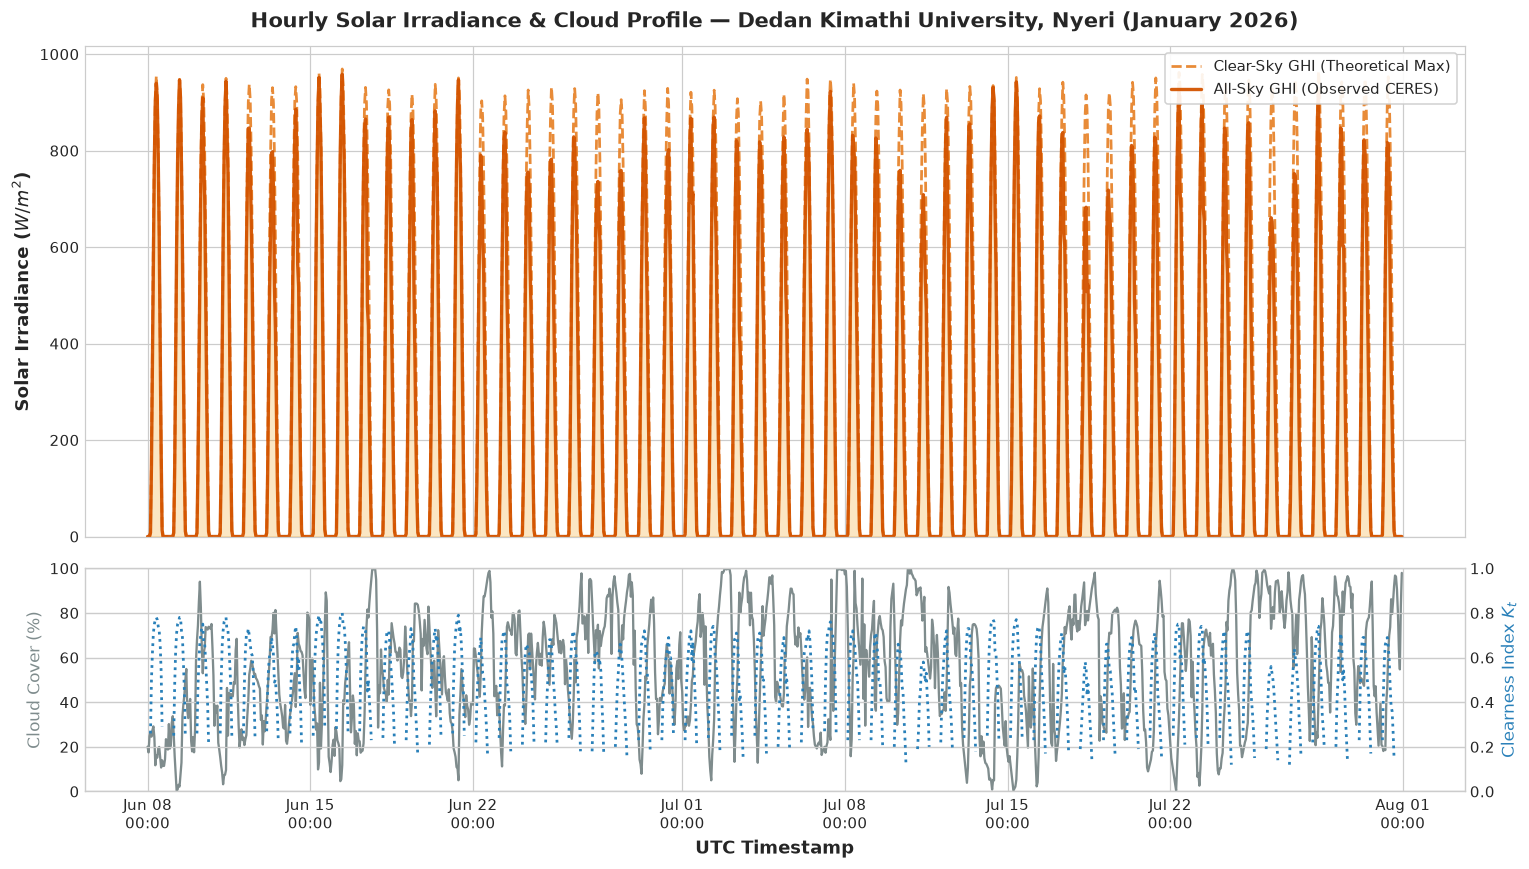

In [29]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})

# Upper panel: GHI vs Clear-Sky GHI
ax1.plot(sub_hourly_dekut.index, sub_hourly_dekut['clrsky_ghi'], color='#e67e22', linestyle='--', linewidth=1.8, label='Clear-Sky GHI (Theoretical Max)', alpha=0.9)
ax1.plot(sub_hourly_dekut.index, sub_hourly_dekut['ghi'], color='#d35400', linewidth=2.2, label='All-Sky GHI (Observed CERES)', alpha=0.95)
ax1.fill_between(sub_hourly_dekut.index, sub_hourly_dekut['ghi'], color='#f39c12', alpha=0.25)
ax1.set_ylabel('Solar Irradiance ($W/m^2$)', fontsize=12, fontweight='bold')
ax1.set_title('Hourly Solar Irradiance & Cloud Profile — Dedan Kimathi University, Nyeri (January 2026)', fontsize=14, fontweight='bold', pad=12)
ax1.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
ax1.set_ylim(bottom=0)

# Lower panel: Cloud Amount & Clearness Index
ax2.plot(sub_hourly_dekut.index, sub_hourly_dekut['cloud_amt'], color='#7f8c8d', linewidth=1.5, label='Cloud Cover (%)')
ax2_twin = ax2.twinx()
ax2_twin.plot(sub_hourly_dekut.index, sub_hourly_dekut['kt'], color='#2980b9', linewidth=1.8, label='Clearness Index ($K_t$)', linestyle=':')
ax2.set_ylabel('Cloud Cover (%)', color='#7f8c8d', fontsize=11)
ax2_twin.set_ylabel('Clearness Index $K_t$', color='#2980b9', fontsize=11)
ax2.set_xlabel('UTC Timestamp', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 100)
ax2_twin.set_ylim(0, 1.0)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d\n%H:%M'))

plt.tight_layout()
plt.show()


### Plot 2: Solar Energy Triad (GHI, DNI, DHI) Decomposition at DeKUT
Breaking down total irradiance into beam (DNI) and diffuse (DHI) components is essential for solar photovoltaic and rooftop system design at the university.

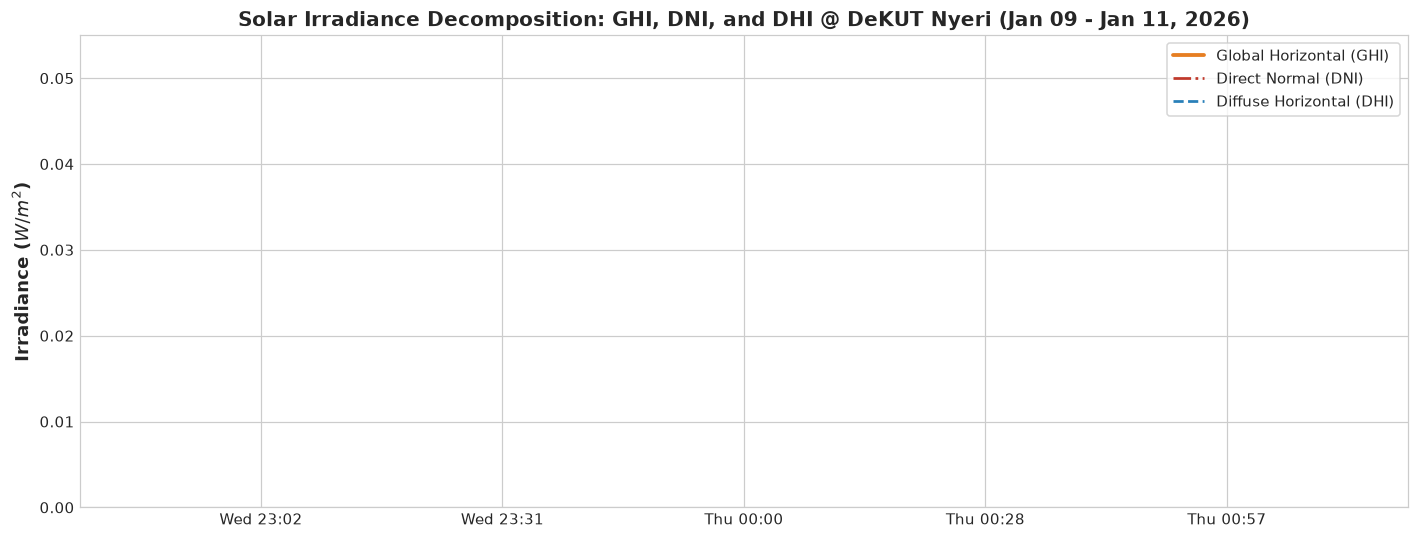

In [30]:
# Zoom in on 3 consecutive diurnal cycles
window = slice("2026-01-09", "2026-01-11")
sample = sub_hourly_dekut.loc[window]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(sample.index, sample['ghi'], label='Global Horizontal (GHI)', color='#e67e22', linewidth=2.5)
ax.plot(sample.index, sample['dni'], label='Direct Normal (DNI)', color='#c0392b', linewidth=1.8, linestyle='-.')
ax.plot(sample.index, sample['dhi'], label='Diffuse Horizontal (DHI)', color='#2980b9', linewidth=1.8, linestyle='--')

ax.set_ylabel('Irradiance ($W/m^2$)', fontsize=12, fontweight='bold')
ax.set_title('Solar Irradiance Decomposition: GHI, DNI, and DHI @ DeKUT Nyeri (Jan 09 - Jan 11, 2026)', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', frameon=True, facecolor='white')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()


## 6. Meteorological & Thermal Dynamics at DeKUT (Nyeri, 2026)

DeKUT sits at an elevation of ~1,780 meters in the central Kenyan highlands between Mount Kenya and the Aberdare Range. Let's analyze its 2026 thermal envelope ($T_{max}$, $T_{min}$, $T_{mean}$) alongside precipitation.

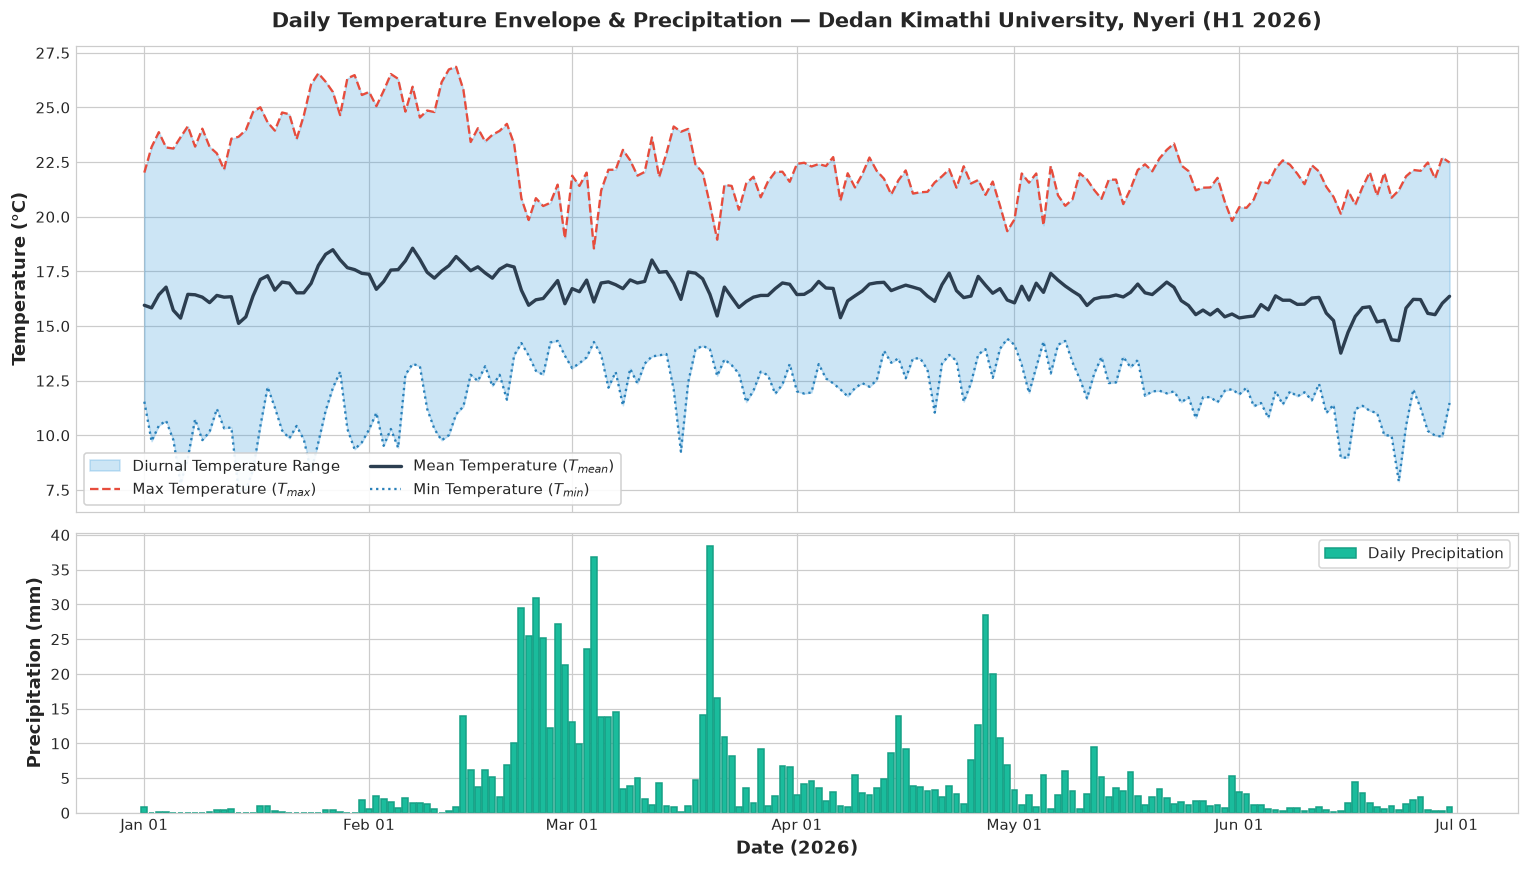

In [31]:
# Extract daily metrics for DeKUT
loc_daily_col = df_dekut_2026.columns.levels[0][0]
sub_daily_dekut = df_dekut_2026[loc_daily_col]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})

# Top: Temperature Envelope for DeKUT Nyeri
ax1.fill_between(sub_daily_dekut.index, sub_daily_dekut['tmin'], sub_daily_dekut['tmax'], color='#3498db', alpha=0.25, label='Diurnal Temperature Range')
ax1.plot(sub_daily_dekut.index, sub_daily_dekut['tmax'], color='#e74c3c', linewidth=1.5, label='Max Temperature ($T_{max}$)', linestyle='--')
ax1.plot(sub_daily_dekut.index, sub_daily_dekut['temp'], color='#2c3e50', linewidth=2.2, label='Mean Temperature ($T_{mean}$)')
ax1.plot(sub_daily_dekut.index, sub_daily_dekut['tmin'], color='#2980b9', linewidth=1.5, label='Min Temperature ($T_{min}$)', linestyle=':')
ax1.set_ylabel('Temperature (°C)', fontsize=12, fontweight='bold')
ax1.set_title('Daily Temperature Envelope & Precipitation — Dedan Kimathi University, Nyeri (H1 2026)', fontsize=14, fontweight='bold', pad=12)
ax1.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, ncol=2)

# Bottom: Rainfall hyetograph for DeKUT Nyeri
ax2.bar(sub_daily_dekut.index, sub_daily_dekut['rain'], color='#1abc9c', width=0.8, edgecolor='#16a085', label='Daily Precipitation')
ax2.set_ylabel('Precipitation (mm)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Date (2026)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True, facecolor='white')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

plt.tight_layout()
plt.show()


## 7. Agroclimatology & Soil Moisture at Nyeri (`community='AG'`)

Nyeri County is a premier agricultural heartland for coffee, tea, and horticulture. NASA POWER's **Agroclimatology (`AG`)** community delivers critical parameters:
* **`GWETROOT`**: Root zone soil wetness (0 to 1).
* **`GWETTOP`**: Surface soil wetness (0 to 1).
* **`EVLAND`**: Land evapotranspiration ($mm/day$).
* **`PRECTOTCORR`**: Total corrected precipitation ($mm/day$).

Let's query DeKUT / Nyeri under `community='AG'` for 2026 to see soil moisture dynamics during the 2026 "Long Rains" season (March–May).

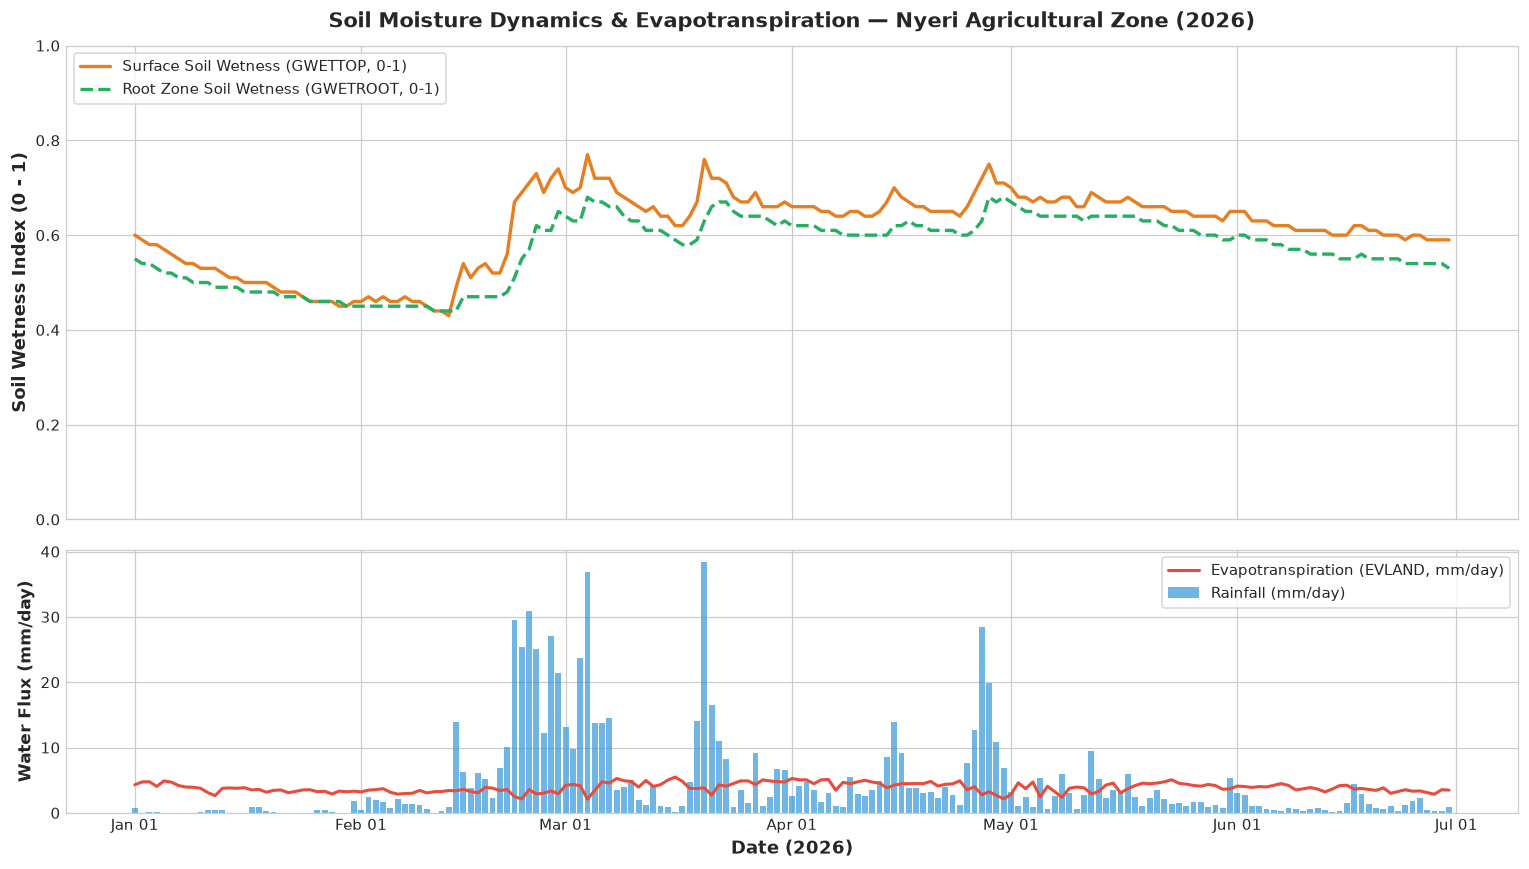

In [32]:
# Query Agroclimatology dataset for DeKUT / Nyeri in 2026
df_agri_dekut = query_nasa_power(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    variables=["soil_moisture_top", "soil_moisture_root", "evaporation", "rain", "temp"],
    community="AG",
    resolution="daily",
    start_date="2026-01-01",
    end_date="2026-06-30",
    format="wide"
)

agri_loc = df_agri_dekut.columns.levels[0][0]
sub_agri = df_agri_dekut[agri_loc]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [1.8, 1]})

# Top: Soil Moisture Layers
ax1.plot(sub_agri.index, sub_agri['soil_moisture_top'], color='#e67e22', linewidth=2.2, label='Surface Soil Wetness (GWETTOP, 0-1)')
ax1.plot(sub_agri.index, sub_agri['soil_moisture_root'], color='#27ae60', linewidth=2.2, linestyle='--', label='Root Zone Soil Wetness (GWETROOT, 0-1)')
ax1.set_ylabel('Soil Wetness Index (0 - 1)', fontsize=12, fontweight='bold')
ax1.set_title('Soil Moisture Dynamics & Evapotranspiration — Nyeri Agricultural Zone (2026)', fontsize=14, fontweight='bold', pad=12)
ax1.set_ylim(0, 1.0)
ax1.legend(loc='upper left', frameon=True, facecolor='white')

# Bottom: Rainfall & Evapotranspiration
ax2.bar(sub_agri.index, sub_agri['rain'], color='#3498db', alpha=0.7, width=0.8, label='Rainfall (mm/day)')
ax2.plot(sub_agri.index, sub_agri['evaporation'], color='#e74c3c', linewidth=2.0, label='Evapotranspiration (EVLAND, mm/day)')
ax2.set_ylabel('Water Flux (mm/day)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Date (2026)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True, facecolor='white')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

plt.tight_layout()
plt.show()


## 8. Multi-Location Spatial Comparison (Featuring DeKUT)

The wrapper seamlessly handles concurrent queries across multiple locations via `ThreadPoolExecutor`.
Let's benchmark **DeKUT (Nyeri)** against three other contrasting Kenyan eco-climatic zones in **2026**:
1. **DeKUT, Nyeri**: Mount Kenya / Aberdares highland (`-0.398, 36.958`)
2. **Nairobi**: Highland subtropical urban (`-1.286, 36.817`)
3. **Lodwar / Turkana**: Arid Northern Desert, high solar potential (`3.119, 35.597`)
4. **Mombasa**: Coastal tropical humid (`-4.043, 39.668`)

In [33]:
target_locations = [
    {"name": "DeKUT (Nyeri Highland)", "lat": DEKUT_NYERI_LAT, "lon": DEKUT_NYERI_LON},
    {"name": "Nairobi (Urban)", "lat": -1.286, "lon": 36.817},
    {"name": "Lodwar (Turkana Desert)", "lat": 3.119, "lon": 35.597},
    {"name": "Mombasa (Coast)", "lat": -4.043, "lon": 39.668},
]

# Single concurrent multi-point query for 2026
df_multi = query_nasa_power(
    locations=target_locations,
    variables=["ghi", "temp", "rh", "rain"],
    resolution="daily",
    start_date="2026-01-01",
    end_date="2026-03-31",
    format="long"
)

print(f"Total multi-station records: {len(df_multi)}")
display(df_multi.groupby(["location", "variable"])["value"].mean().unstack())


Total multi-station records: 1440


variable,ghi,rain,rh,temp
location,,,,
DeKUT (Nyeri Highland),6.135539,5.801556,75.399444,16.913111
Lodwar (Turkana Desert),6.131910,0.970333,42.464778,29.968333
Mombasa (Coast),5.952992,3.623111,73.062222,27.652444
Nairobi (Urban),6.375112,3.040556,66.356444,20.808444


### Plot 4: Regional Solar Irradiance & Temperature Distributions (2026)
Comparing daily insolation ($kWh/m^2/day$) and temperature profiles between DeKUT (Nyeri) and other regions.

<>:8: SyntaxWarning: invalid escape sequence '\c'
<>:8: SyntaxWarning: invalid escape sequence '\c'
C:\Users\SAMMY\AppData\Local\Temp\ipykernel_21860\1099114486.py:8: SyntaxWarning: invalid escape sequence '\c'
  ax1.set_ylabel('Insolation ($kW\cdot h/m^2/day$)', fontsize=11, fontweight='bold')
C:\Users\SAMMY\AppData\Local\Temp\ipykernel_21860\1099114486.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ghi_data, x='location', y='value', palette='YlOrRd', ax=ax1, width=0.5)
C:\Users\SAMMY\AppData\Local\Temp\ipykernel_21860\1099114486.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=temp_data, x='location', y='value', palette='coolwarm', ax=ax2, width=0.5)


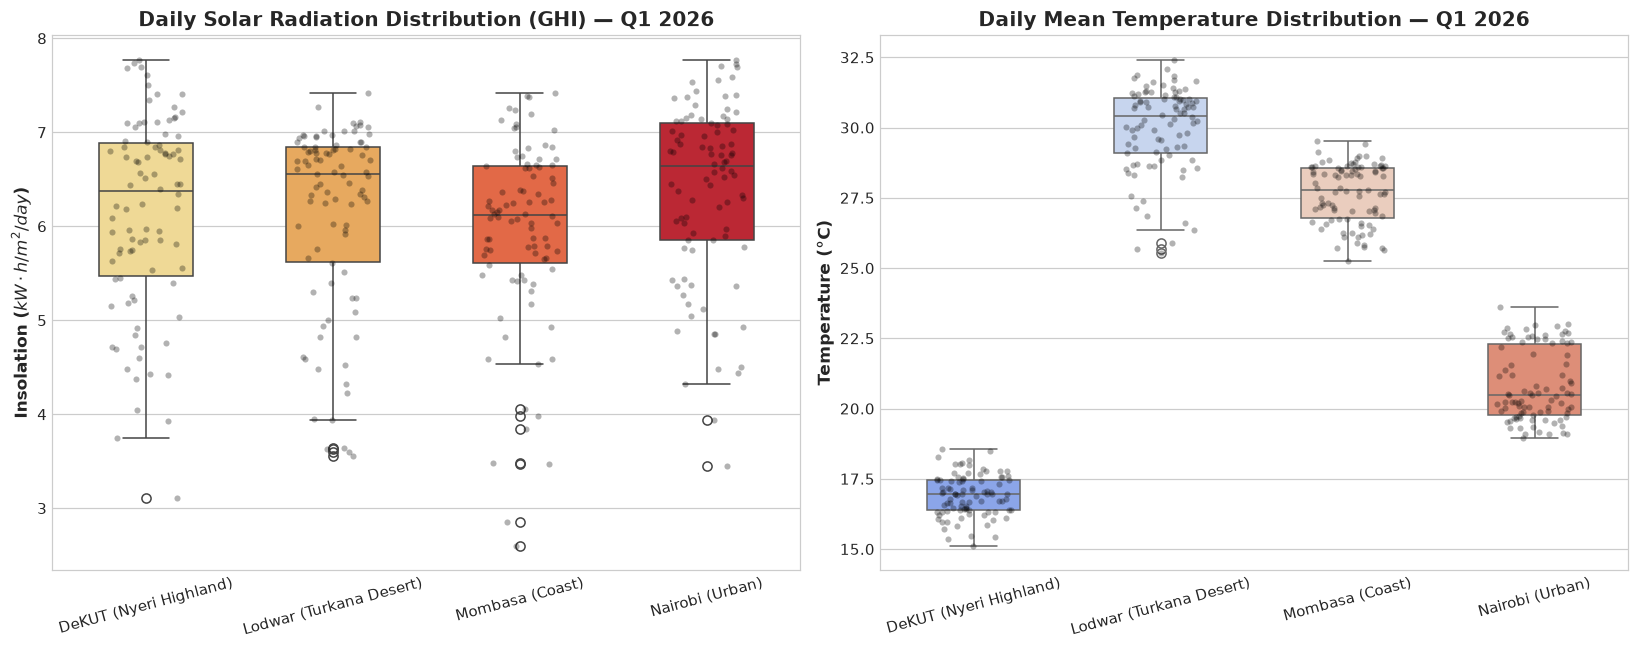

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Boxplot of Solar Radiation (GHI)
ghi_data = df_multi[df_multi['variable'] == 'ghi']
sns.boxplot(data=ghi_data, x='location', y='value', palette='YlOrRd', ax=ax1, width=0.5)
sns.stripplot(data=ghi_data, x='location', y='value', color='black', alpha=0.3, jitter=0.2, ax=ax1, size=4)
ax1.set_title('Daily Solar Radiation Distribution (GHI) — Q1 2026', fontsize=13, fontweight='bold')
ax1.set_ylabel('Insolation ($kW\cdot h/m^2/day$)', fontsize=11, fontweight='bold')
ax1.set_xlabel('')
ax1.tick_params(axis='x', rotation=15)

# Boxplot of Temperature
temp_data = df_multi[df_multi['variable'] == 'temp']
sns.boxplot(data=temp_data, x='location', y='value', palette='coolwarm', ax=ax2, width=0.5)
sns.stripplot(data=temp_data, x='location', y='value', color='black', alpha=0.3, jitter=0.2, ax=ax2, size=4)
ax2.set_title('Daily Mean Temperature Distribution — Q1 2026', fontsize=13, fontweight='bold')
ax2.set_ylabel('Temperature (°C)', fontsize=11, fontweight='bold')
ax2.set_xlabel('')
ax2.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


## 9. Multi-Year Monthly Climatology & Seasonality at DeKUT, Nyeri

By setting `resolution='monthly'`, we can query multi-year seasonal cycles without downloading high-frequency hourly files.
Let's inspect the historical monthly rainfall and solar cycle over 5 years (2019–2023) to highlight Nyeri's bimodal monsoon patterns:
* **Long Rains**: March – May (MAM)
* **Short Rains**: October – December (OND)

<>:25: SyntaxWarning: invalid escape sequence '\c'
<>:25: SyntaxWarning: invalid escape sequence '\c'
C:\Users\SAMMY\AppData\Local\Temp\ipykernel_21860\81294266.py:25: SyntaxWarning: invalid escape sequence '\c'
  ax1.set_ylabel('Solar GHI ($kW\cdot h/m^2/day$)', color=color_solar, fontsize=12, fontweight='bold')


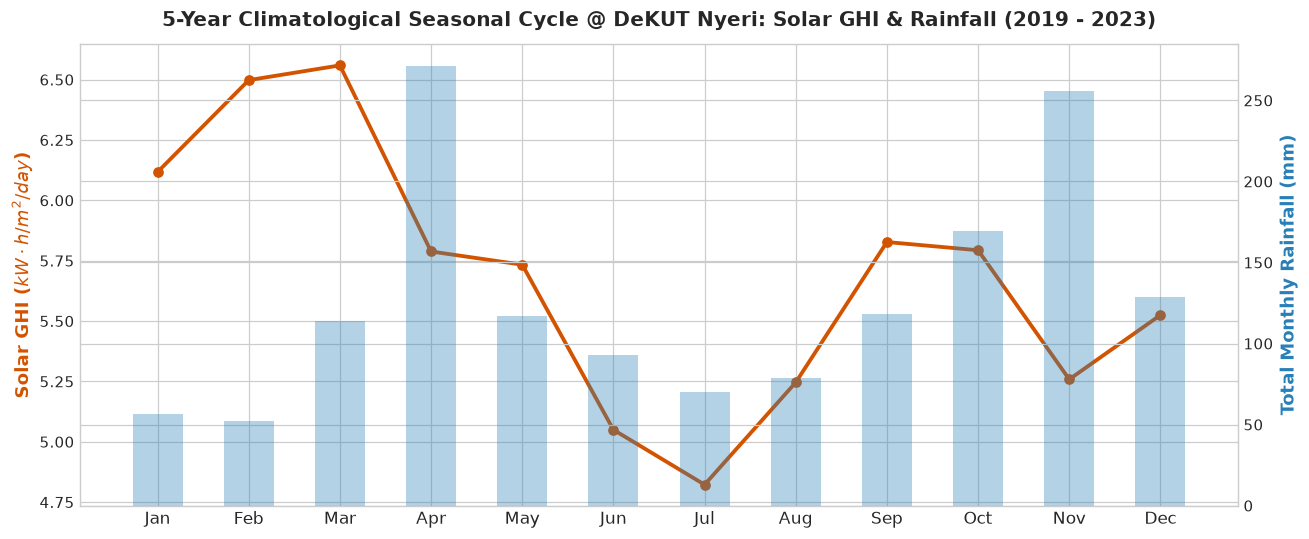

In [35]:
# Query 5 years of monthly climate aggregates for DeKUT, Nyeri
df_monthly = query_nasa_power(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    variables=["ghi", "temp", "rain"],
    resolution="monthly",
    start_date="2019",
    end_date="2023",
    format="wide"
)

loc_mon = df_monthly.columns.levels[0][0]
sub_mon = df_monthly[loc_mon].copy()
sub_mon['month'] = sub_mon.index.month

# Compute 5-year climatological monthly averages for Nyeri
monthly_climatology = sub_mon.groupby('month').mean()
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax1 = plt.subplots(figsize=(12, 5))

# Solar insolation curve
color_solar = '#d35400'
ax1.plot(monthly_climatology.index, monthly_climatology['ghi'], color=color_solar, marker='o', linewidth=2.5, label='Solar GHI')
ax1.set_ylabel('Solar GHI ($kW\cdot h/m^2/day$)', color=color_solar, fontsize=12, fontweight='bold')
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(month_labels, fontsize=11)
ax1.set_title('5-Year Climatological Seasonal Cycle @ DeKUT Nyeri: Solar GHI & Rainfall (2019 - 2023)', fontsize=13, fontweight='bold', pad=12)

# Rainfall bars on secondary axis
ax2 = ax1.twinx()
color_rain = '#2980b9'
ax2.bar(monthly_climatology.index, monthly_climatology['rain'] * 30.4, color=color_rain, alpha=0.35, width=0.55, label='Monthly Rainfall (est. mm)')
ax2.set_ylabel('Total Monthly Rainfall (mm)', color=color_rain, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## 10. Performance & On-Disk Parquet Caching

The wrapper incorporates transparent on-disk caching via Parquet files in `./mw_cache`:
1. Every query generates a SHA-256 fingerprint based on coordinates, temporal resolution, community, and variables.
2. If repeated within the cache time-to-live (`cache_ttl_hours=168.0` / 7 days), data is instantly read from disk with zero HTTP latency.
3. This prevents rate-limiting and makes interactive Jupyter notebook sessions extremely responsive.

Let's measure the cache speedup for DeKUT 2026 data:

In [36]:
import time

# Repeated call for DeKUT Nyeri 2026 data - hits local Parquet cache
t0 = time.time()
cached_df = query_nasa_power(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    variables=["ghi", "temp"],
    resolution="daily",
    start_date="2026-01-01",
    end_date="2026-06-30"
)
t_elapsed = (time.time() - t0) * 1000

print(f"Parquet cache hit retrieved in: {t_elapsed:.2f} ms!")


Parquet cache hit retrieved in: 37.15 ms!


## 11. Summary & Academic Citation

The `masharikiweather.wrappers.nasa_power` module provides:
1. **Zero Key Needed:** Public REST API accessible out-of-the-box.
2. **Effortless Retrieval:** 1–2 lines of code to fetch clean DataFrames.
3. **Data Latency Awareness:** Probes exact latest populated dates for both hourly and daily queries so users never get surprised by missing solar or weather data.
4. **Comprehensive Coverage:** From hourly CERES solar flux to root-zone soil wetness and multi-year climatologies.
5. **Automatic Resilience:** Built-in rate-limiting, retries, auto-chunking, and Parquet caching.

### How to Cite NASA POWER in Publications:
If using NASA POWER data in academic publications or technical reports, please cite:
> NASA Prediction Of Worldwide Energy Resources (POWER) Project.
> Data derived from NASA Langley Research Center POWER Project funded through the NASA Earth Science Directorate Applied Sciences Program.
> Website: https://power.larc.nasa.gov/
